Import libraries and train model

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Training dataset
train_data = pd.DataFrame({
    'failed_logins': [0, 1, 2, 0, 7, 4, 5, 1, 6, 3, 0, 8],
    'login_hour': [10, 9, 15, 12, 2, 23, 11, 18, 14, 1, 8, 3],
    'new_device': [0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1],
    'download_mb': [40, 80, 720, 60, 150, 400, 200, 50, 300, 600, 90, 500],
    'label': ['Normal', 'Normal', 'Suspicious', 'Normal',
              'Suspicious', 'Suspicious', 'Suspicious',
              'Normal', 'Suspicious', 'Suspicious',
              'Normal', 'Suspicious']
})

features = ['failed_logins', 'login_hour',
            'new_device', 'download_mb']

X = train_data[features]
y = train_data['label']

model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

print("Model trained successfully!")


Model trained successfully!


Q1: Baseline Predictions with Confidence

In [2]:

samples = pd.DataFrame([
    {'account_id': 'ACC-1001', 'ip_address': '192.168.10.24',
     'failed_logins': 0, 'login_hour': 10, 'new_device': 0, 'download_mb': 40},

    {'account_id': 'ACC-1002', 'ip_address': '10.0.4.18',
     'failed_logins': 7, 'login_hour': 2, 'new_device': 1, 'download_mb': 150},

    {'account_id': 'ACC-1003', 'ip_address': '172.16.8.90',
     'failed_logins': 1, 'login_hour': 15, 'new_device': 0, 'download_mb': 720},

    {'account_id': 'ACC-1004', 'ip_address': '192.168.20.11',
     'failed_logins': 4, 'login_hour': 23, 'new_device': 1, 'download_mb': 400},

    {'account_id': 'ACC-1005', 'ip_address': '10.1.1.9',
     'failed_logins': 2, 'login_hour': 9, 'new_device': 0, 'download_mb': 80}
])

samples['prediction'] = model.predict(samples[features])

samples['confidence'] = model.predict_proba(
    samples[features]
).max(axis=1).round(3)

display(samples)

print("Lowest Confidence Record:")
print(samples.loc[samples['confidence'].idxmin()])


,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,1.0
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.0
2,ACC-1003,172.16.8.90,1,15,0,720,Normal,1.0
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.0
4,ACC-1005,10.1.1.9,2,9,0,80,Suspicious,1.0


Lowest Confidence Record:
account_id            ACC-1001
ip_address       192.168.10.24
failed_logins                0
login_hour                  10
new_device                   0
download_mb                 40
prediction              Normal
confidence                 1.0
Name: 0, dtype: object


: Feature Importance and Explanation

,feature,importance
0,failed_logins,1.0
1,login_hour,0.0
2,new_device,0.0
3,download_mb,0.0


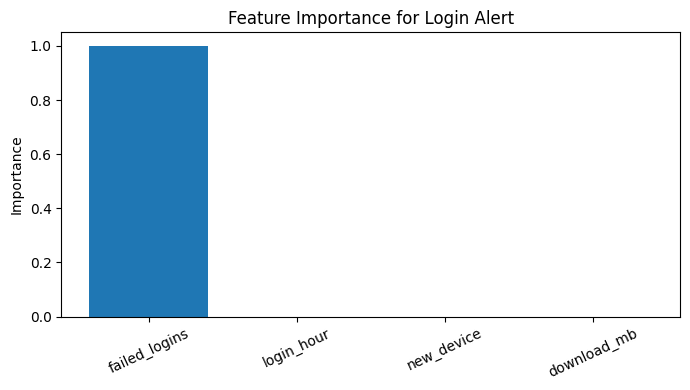

Top Three Feature Explanations:
failed_logins was frequently used by the model.
login_hour was frequently used by the model.
new_device was frequently used by the model.
Feature importance does not prove causation.


In [3]:

importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

display(importance)

plt.figure(figsize=(7, 4))
plt.bar(importance['feature'], importance['importance'])
plt.title('Feature Importance for Login Alert')
plt.ylabel('Importance')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Top Three Feature Explanations:")

for feature in importance.head(3)['feature']:
    print(feature, "was frequently used by the model.")

print("Feature importance does not prove causation.")


Q3: Controlled Sensitivity Test

In [4]:

baseline = samples.iloc[[4]].copy()

changed = baseline.copy()
changed['failed_logins'] = 8

baseline_prediction = model.predict(baseline[features])[0]
baseline_confidence = model.predict_proba(baseline[features]).max()

changed_prediction = model.predict(changed[features])[0]
changed_confidence = model.predict_proba(changed[features]).max()

result = pd.DataFrame({
    'Test': ['Baseline', 'Changed'],
    'Failed Logins': [2, 8],
    'Prediction': [baseline_prediction, changed_prediction],
    'Confidence': [
        round(baseline_confidence, 3),
        round(changed_confidence, 3)
    ]
})

display(result)

print("Only failed_logins was changed from 2 to 8.")
print("Other features remained the same.")
print("The predictions show the model's sensitivity.")


,Test,Failed Logins,Prediction,Confidence
0,Baseline,2,Suspicious,1.0
1,Changed,8,Suspicious,1.0


Only failed_logins was changed from 2 to 8.
Other features remained the same.
The predictions show the model's sensitivity.


Q4: Privacy Masking and Responsible-Use Rules

In [5]:

def mask_ip(ip):
    parts = str(ip).split('.')

    if len(parts) == 4:
        return f'{parts[0]}.{parts[1]}.xxx.xxx'

    return '<MASKED_IP>'


def mask_account(account_id):
    text = str(account_id)
    return text[:4] + '***' + text[-2:]


samples['masked_ip'] = samples['ip_address'].apply(mask_ip)

samples['masked_account'] = samples['account_id'].apply(
    mask_account
)

display(samples[[
    'masked_account',
    'masked_ip',
    'prediction',
    'confidence'
]])

privacy_rules = [
    'Mask identifiers before display or export.',
    'Use sanitized data in classroom notebooks.',
    'Restrict access to unmasked records.',
    'Require human review for high-risk action.'
]

print("Privacy and Responsible-Use Rules:")

for rule in privacy_rules:
    print("-", rule)


,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,1.0
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.0
2,ACC-***03,172.16.xxx.xxx,Normal,1.0
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.0
4,ACC-***05,10.1.xxx.xxx,Suspicious,1.0


Privacy and Responsible-Use Rules:
- Mask identifiers before display or export.
- Use sanitized data in classroom notebooks.
- Restrict access to unmasked records.
- Require human review for high-risk action.


: Responsible Alert Generation

In [6]:

def numeric_reason(row):
    reasons = []

    if row['failed_logins'] >= 5:
        reasons.append('many failed logins')

    if row['new_device'] == 1:
        reasons.append('new device')

    if row['login_hour'] < 6 or row['login_hour'] > 22:
        reasons.append('unusual login time')

    if row['download_mb'] >= 500:
        reasons.append('large data download')

    return ', '.join(reasons) if reasons else 'no strong warning'


def make_alert(row):
    reason = numeric_reason(row)

    if row['prediction'] == 'Suspicious':
        severity = 'High'
        action = 'Verify, contain if required, and report.'

    elif row['confidence'] < 0.70:
        severity = 'Medium'
        action = 'Send for analyst review before action.'

    else:
        severity = 'Low'
        action = 'Continue normal monitoring.'

    human_review = 'Yes' if severity in ['High', 'Medium'] else 'No'

    return severity, reason, action, human_review


alerts = samples.apply(make_alert, axis=1)

samples[[
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]] = pd.DataFrame(alerts.tolist(), index=samples.index)

display(samples[[
    'masked_account',
    'prediction',
    'confidence',
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]])

print("Lab 4 Completed Successfully!")


,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.0,High,"many failed logins, new device, unusual login ...","Verify, contain if required, and report.",Yes
2,ACC-***03,Normal,1.0,Low,large data download,Continue normal monitoring.,No
3,ACC-***04,Suspicious,1.0,High,"new device, unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Suspicious,1.0,High,no strong warning,"Verify, contain if required, and report.",Yes


Lab 4 Completed Successfully!
